In [2]:
import pandas as pd

df = pd.read_csv('D:\FYP\Code\Dataset\downsampled_data.csv')

Amplitude data only.

They ommitted data preprocessing.

CSI sampling frequency is 100 Hz. But frequency in our downsampled data is 25 Hz.

In [22]:
# Amplitude data only.
X1 = df.iloc[:, 2:66]
X2 = df.iloc[:, 130:194]
X = pd.concat([X1, X2], axis=1)

Y = df.iloc[:, -1]

In [23]:
X

,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,amplitude10_1,...,amplitude55_2,amplitude56_2,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2
0,118.726577,5.0,29.732137,31.953091,33.241540,33.105891,32.249031,30.805844,29.068884,26.870058,...,-2.089942,-2.062606,-2.034444,-2.003204,-2.000559,-2.034444,-2.134113,-2.253113,-2.459276,-2.593043
1,118.726577,5.0,28.600699,30.000000,31.064449,30.886890,29.546573,28.792360,26.925824,24.331050,...,-1.604117,-1.570796,-1.536327,-1.496857,-1.490966,-1.527345,-1.616220,-1.719686,-1.923787,-2.013171
2,118.726577,5.0,29.529646,30.886890,32.756679,33.015148,31.890437,31.112698,28.425341,25.806976,...,2.790148,2.819842,2.840672,2.863293,2.878598,2.846152,2.718739,2.634494,2.427502,2.253113
3,118.726577,5.0,29.000000,31.000000,32.062439,32.249031,31.780497,30.364453,28.231188,25.942244,...,0.739975,0.762147,0.809784,0.811034,0.840897,0.815692,0.718830,0.574305,0.418224,0.244979
4,118.726577,5.0,28.861739,30.805844,31.575307,32.249031,32.015621,30.066593,28.284271,25.709920,...,2.089942,2.105751,2.167973,2.158799,2.169215,2.147172,2.055274,1.923787,1.719686,1.570796
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116570,118.726577,5.0,7.280110,9.848858,11.661904,13.892444,16.124515,17.000000,17.464249,17.464249,...,-0.404892,-0.358771,-0.339293,-0.270947,-0.218669,-0.231091,-0.185348,-0.211093,-0.266252,-0.321751
116571,118.726577,5.0,13.000000,18.248288,24.083189,28.160256,31.256999,33.376639,33.734256,33.955854,...,0.374334,0.424194,0.463648,0.512389,0.535811,0.564569,0.588003,0.607802,0.540420,0.512389
116572,118.726577,5.0,13.038405,18.027756,24.041631,28.160256,31.320920,32.572995,34.176015,34.014703,...,0.478352,0.489957,0.526066,0.572966,0.632749,0.665969,0.679414,0.664046,0.610726,0.531724
116573,118.726577,5.0,11.180340,16.124515,22.022716,26.019224,29.017236,31.064449,32.249031,32.388269,...,-2.809533,-2.782822,-2.740364,-2.690140,-2.642246,-2.615526,-2.611377,-2.618314,-2.659079,-2.723368


In [24]:
Y

0         4
1         4
2         4
3         4
4         4
         ..
116570    0
116571    0
116572    0
116573    0
116574    0
Name: activity, Length: 116575, dtype: int64

### Feature extraction

They proposed the mean and variance of CSI amplitude to be a couple of good indicators for intrusion detection. Denote the feature couple as F[α, β], where α represents the mean and β represents the variance of CSI amplitude respectively.

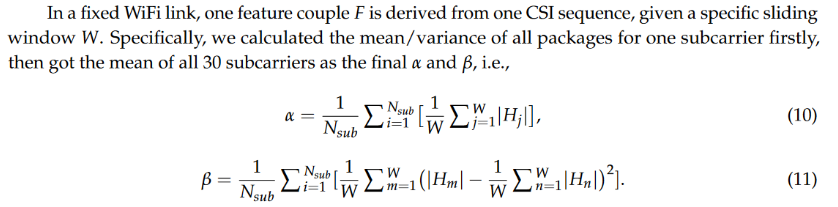

In [47]:
# Feature Extraction
window_size = 25
num_subcarriers = 64 * 2

features = []
labels = []

In [46]:
alpha = 0   # Alpha represents the mean of amplitude data in a window.
beta = 0    # Beta represents the varience of amplitude data in a window.

# In a sliding window of 25 samples, calculate the mean/variance of all packages for one subcarrier firstly, 
# then get the mean of all 64*2 subcarriers as the final α and β

# Window size = 25 samples; Considering 1 second of data


for window in range(0, len(X), 25):

    sum_amp_means = 0
    sum_amp_variences = 0

    for subcarrier in range(0, 64*2):
        sum_subcarrier_amplitudes = 0
        for i in range(window, window + 25):
            cell_value = X.iloc[i, subcarrier]
            sum_subcarrier_amplitudes += cell_value
            # sum_subcarrier_means += X.iloc[window, subcarrier].mean()
            # sum_subcarrier_variences += X.iloc[window, subcarrier].var()
        subcarrier_amp_mean = sum_subcarrier_amplitudes/25
        sum_amp_means += subcarrier_amp_mean

        sum_subcarrier_varience = 0
        for j in range (window, window +25):
            cell_value = X.iloc[j, subcarrier]
            sum_subcarrier_varience += (cell_value - subcarrier_amp_mean)**2
        subcarrier_amp_varience = sum_subcarrier_varience/25
        sum_amp_variences += subcarrier_amp_varience
        
        
    alpha = sum_amp_means/(64*2)
    beta = sum_amp_variences/(64*2)
    print('Alpha:', alpha, 'Beta:', beta)


Window: 1 Mean: 9.293428302496437 Variance: 3.091090673641717
Window: 2 Mean: 9.338530019660439 Variance: 3.138108266226241
Window: 3 Mean: 9.38321617743281 Variance: 2.7824011482993516
Window: 4 Mean: 9.57423768734613 Variance: 2.00367511593993
Alpha: 9.293428302496435 Beta: 2.9674470466960488
Alpha: 9.338530019660434 Beta: 3.0125839355771924
Alpha: 9.38321617743281 Beta: 2.6711051023673784
Alpha: 9.574237687346134 Beta: 1.923528111302333
Alpha: 9.744705192039396 Beta: 1.711962638000737
Alpha: 9.43770521099205 Beta: 2.565430297057808
Alpha: 9.376180808411924 Beta: 1.9403753716085854
Alpha: 9.328060579870094 Beta: 2.249750619442025
Alpha: 9.32269991972481 Beta: 2.9967208679382655
Alpha: 9.319601642529134 Beta: 2.0519372396899365
Alpha: 9.488714074041942 Beta: 1.6445895412003888
Alpha: 9.199904229423424 Beta: 2.446837929901793
Alpha: 9.253833586397153 Beta: 2.3439054815535307
Alpha: 9.16024117520792 Beta: 2.09854598222466
Alpha: 9.357278018891101 Beta: 2.4667985835495836
Alpha: 9.035138

In [48]:
for window_start in range(0, len(X) - window_size + 1, window_size):
    window_end = window_start + window_size
    window_data = X.iloc[window_start:window_end]

    sum_amp_means = 0
    sum_amp_variences = 0
    
    for subcarrier in range(num_subcarriers):
        subcarrier_amplitudes = window_data.iloc[:, subcarrier]
        subcarrier_amp_mean = subcarrier_amplitudes.mean()
        subcarrier_amp_varience = subcarrier_amplitudes.var()

        sum_amp_means += subcarrier_amp_mean
        sum_amp_variences += subcarrier_amp_varience

    alpha = sum_amp_means / num_subcarriers
    beta = sum_amp_variences / num_subcarriers
    print('Alpha:', alpha, 'Beta:', beta)

    features.append([alpha, beta])
    labels.append(Y.iloc[window_end - 1])  # Assuming the label for the window is the label of the last sample in the window


Alpha: 9.293428302496437 Beta: 3.0910906736417174
Alpha: 9.338530019660435 Beta: 3.138108266226242
Alpha: 9.383216177432809 Beta: 2.782401148299351
Alpha: 9.574237687346134 Beta: 2.003675115939929
Alpha: 9.744705192039394 Beta: 1.7832944145841
Alpha: 9.43770521099205 Beta: 2.6723232261018803
Alpha: 9.376180808411924 Beta: 2.0212243454256105
Alpha: 9.328060579870096 Beta: 2.343490228585444
Alpha: 9.32269991972481 Beta: 3.121584237435694
Alpha: 9.319601642529134 Beta: 2.137434624677017
Alpha: 9.48871407404194 Beta: 1.7131141054170718
Alpha: 9.199904229423424 Beta: 2.5487895103143687
Alpha: 9.253833586397153 Beta: 2.4415682099515945
Alpha: 9.16024117520792 Beta: 2.1859853981506876
Alpha: 9.357278018891101 Beta: 2.5695818578641485
Alpha: 9.035138972128417 Beta: 3.0942851349142546
Alpha: 9.380457165813029 Beta: 3.0489628973320975
Alpha: 9.292347471843696 Beta: 2.2879532488798673
Alpha: 9.347934485539303 Beta: 2.93894714279232
Alpha: 9.213270300990258 Beta: 2.9732224998191685
Alpha: 9.236297

Convert features and labels to DataFrame

In [49]:
features_df = pd.DataFrame(features, columns=['alpha', 'beta'])
labels_df = pd.Series(labels)

# Classification Model

Split the data into training and validation sets

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(features_df, labels_df, test_size=0.2, random_state=42)

### SVM Parameters
They adopted the radial basis function (RBF) kernel (a.k.a. Gaussian kernel) as the kernel function so that a non-linear regression model can be constructed. 
This SVM has two such training factors: C which controls overfitting of the model, and γ which controls the degree of nonlinearity of the model. In our system, we set C = 0.8 and γ = 20.

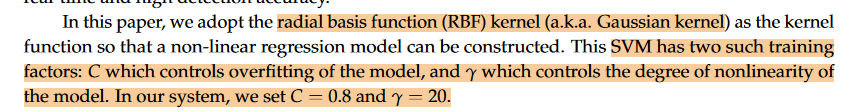

In [51]:
from sklearn import svm

model = svm.SVC(C = 0.8 , gamma = 20 , kernel = 'rbf')

model.fit(X_train, y_train)

SVC(C=0.8, gamma=20)

## Results Evaluation

#### Accuracy Check : 01

In [52]:
accuracy = model.score(X_val, y_val)
print(f'Validation Accuracy: {accuracy * 100:.2f}%')

Validation Accuracy: 52.52%


#### Accuracy Check : 02

In [53]:
y_pred = model.predict(X_val)

In [55]:
y_train

4181    0
332     4
1113    1
751     5
720     5
       ..
4426    4
466     4
3092    0
3772    0
860     5
Length: 3730, dtype: int64

In [54]:
y_pred

array([4, 0, 1, 1, 4, 0, 4, 0, 0, 0, 0, 5, 5, 0, 0, 0, 0, 0, 2, 2, 2, 5,
       0, 0, 0, 0, 1, 4, 0, 1, 0, 2, 0, 0, 0, 4, 1, 4, 4, 1, 0, 0, 4, 5,
       2, 0, 4, 4, 0, 4, 5, 0, 4, 0, 0, 0, 0, 4, 0, 0, 0, 4, 0, 0, 5, 4,
       0, 5, 0, 1, 2, 1, 0, 0, 5, 0, 4, 2, 4, 2, 0, 5, 5, 4, 5, 0, 0, 0,
       0, 0, 2, 0, 4, 1, 4, 4, 0, 5, 2, 0, 5, 1, 3, 4, 0, 0, 1, 0, 0, 0,
       0, 0, 1, 4, 0, 0, 0, 0, 4, 5, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 2,
       0, 5, 4, 0, 0, 0, 4, 0, 5, 0, 0, 0, 4, 0, 2, 0, 0, 4, 0, 2, 2, 4,
       0, 4, 0, 2, 0, 1, 0, 1, 2, 0, 0, 0, 2, 0, 3, 0, 0, 2, 4, 0, 0, 0,
       0, 1, 5, 1, 3, 0, 4, 4, 4, 5, 0, 0, 4, 0, 5, 0, 5, 2, 4, 2, 2, 0,
       0, 2, 1, 0, 0, 0, 0, 2, 1, 0, 0, 4, 0, 0, 4, 1, 0, 0, 0, 5, 1, 1,
       0, 0, 0, 0, 0, 4, 0, 5, 0, 0, 0, 0, 0, 4, 4, 5, 2, 4, 0, 4, 4, 5,
       0, 0, 4, 4, 2, 0, 4, 0, 4, 4, 0, 5, 0, 0, 0, 0, 1, 0, 5, 5, 0, 0,
       0, 1, 0, 0, 1, 2, 4, 0, 2, 0, 1, 4, 4, 0, 0, 0, 0, 0, 5, 4, 0, 3,
       5, 0, 0, 5, 0, 0, 0, 0, 1, 0, 1, 5, 0, 0, 0,

In [56]:
from sklearn import metrics

accuracy = metrics.accuracy_score(y_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.5251875669882101


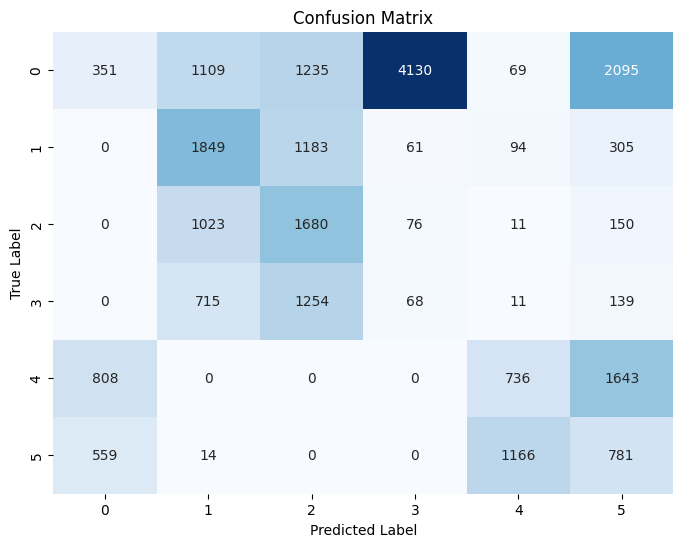

In [30]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val, y_pred, average=None)
recall = recall_score(y_val, y_pred, average=None)
f1 = f1_score(y_val, y_pred, average=None)

# Print results for each class
for class_label in range(6):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.2043
Recall: 0.0390
F1 Score: 0.0656

Class 1:
Precision: 0.3926
Recall: 0.5295
F1 Score: 0.4509

Class 2:
Precision: 0.3139
Recall: 0.5714
F1 Score: 0.4052

Class 3:
Precision: 0.0157
Recall: 0.0311
F1 Score: 0.0209

Class 4:
Precision: 0.3527
Recall: 0.2309
F1 Score: 0.2791

Class 5:
Precision: 0.1527
Recall: 0.3099
F1 Score: 0.2046



# Label Mapping


In [58]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4:
		return 0
	elif prediction == 5:
		return 1
	else:
		return 2

# Night Time


In [41]:
for i in range (len(y_pred)):
	y_pred[i] = predictionMapping(y_pred[i])

y_val = y_val.apply(predictionMapping)

In [42]:
from sklearn import metrics

accuracy = metrics.accuracy_score(y_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.6195069667738478


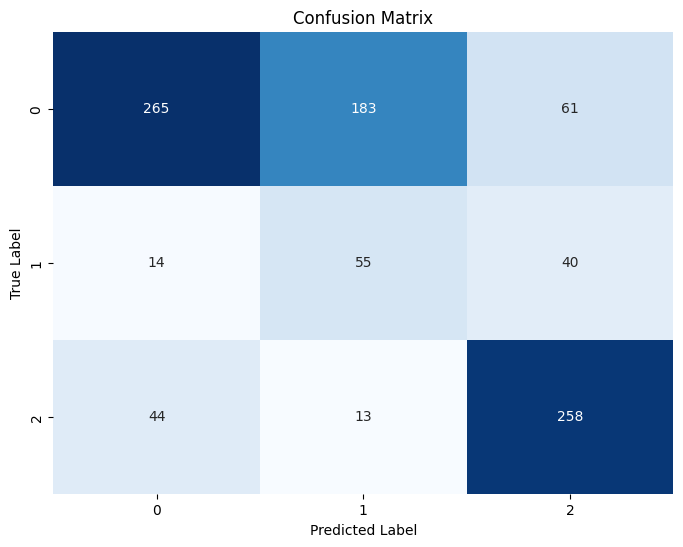

In [43]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [44]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, y_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.6417


In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val, y_pred, average=None)
recall = recall_score(y_val, y_pred, average=None)
f1 = f1_score(y_val, y_pred, average=None)

# Print results for each class
for class_label in range(3):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.8204
Recall: 0.5206
F1 Score: 0.6370

Class 1:
Precision: 0.2191
Recall: 0.5046
F1 Score: 0.3056

Class 2:
Precision: 0.7187
Recall: 0.8190
F1 Score: 0.7656



# Run only upper part until label mapping


In [72]:
night_y_val = []
night_y_pred = []

for i in range (len(y_pred)):
	if y_val.iloc[i] != 5:
		night_y_val.append(predictionMapping(y_val.iloc[i]))
		if y_pred[i] == 5:
			night_y_pred.append(predictionMapping(0))
		else:
			night_y_pred.append(predictionMapping(y_pred[i]))





In [73]:
from sklearn import metrics

accuracy = metrics.accuracy_score(night_y_pred, night_y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.8567961165048543


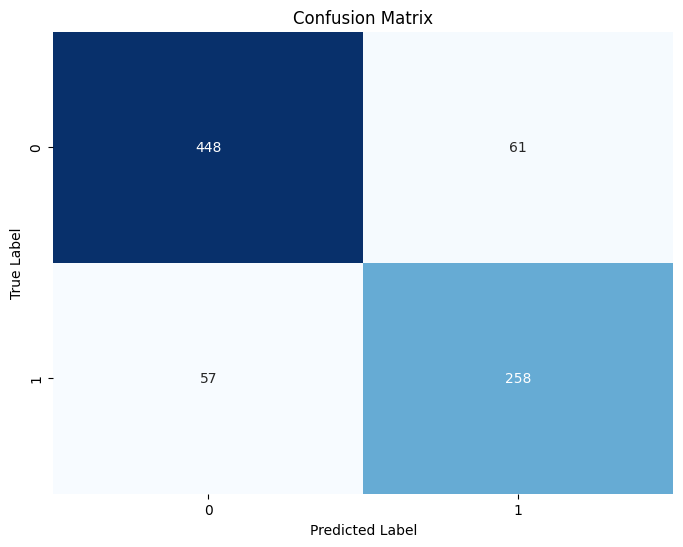

In [74]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(night_y_val, night_y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [76]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(night_y_val, night_y_pred, average=None)
recall = recall_score(night_y_val, night_y_pred, average=None)
f1 = f1_score(night_y_val, night_y_pred, average=None)

# Print results for each class
for class_label in range(2):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.8871
Recall: 0.8802
F1 Score: 0.8836

Class 1:
Precision: 0.8088
Recall: 0.8190
F1 Score: 0.8139

